# 5 · Forecasting volatility through the Covid shock: GARCH, HAR, VIX and an LSTM
A risk manager needs tomorrow's estimate of next month's volatility, and the test that matters is a shock like February-March 2020. This notebook forecasts the **realised volatility of SPY over the next 22 trading days**, made every day from 2019 to October 2026, with five methods:

* **Naive:** the last 22 days' realised volatility.
* **HAR** (Corsi, 2009): a regression on the log of realised variance over the last 1, 5 and 22 days, refit each year.
* **GJR-GARCH(1,1)** with Student-t errors, refit every month on all data to date.
* **VIX:** the market's 30-day implied volatility, used directly and also bias-corrected with a regression fitted on past data.
* **LSTM:** a small recurrent network on the last 22 days of absolute returns, short-term realised variance and VIX, trained on 2000-2016 and validated on 2017-2018.

Accuracy is measured by QLIKE (robust to noise in the volatility proxy) and RMSE, overall and separately for the Covid crash (February-June 2020). Diebold-Mariano tests compare each method with HAR.

In [1]:
import sys, pathlib, os, warnings
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from arch import arch_model
from sklearn.linear_model import LinearRegression
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); DATA = pathlib.Path("../data")
from covidmkt import volatility as vol
d = pd.read_csv(DATA / "spy_vix_2000.csv", index_col=0, parse_dates=True)
r = np.log(d["spy"]).diff().dropna(); vix = d["vix"].loc[r.index] / 100
H = 22
target = vol.forward_realised_vol(r, H)
har = vol.har_features(r)
TEST = pd.Timestamp("2019-01-01")
print(f"{len(r):,} daily returns, {r.index[0]:%b %Y} to {r.index[-1]:%b %Y}; forecasts evaluated from {TEST:%b %Y}")

6,747 daily returns, Jan 2000 to Oct 2026; forecasts evaluated from Jan 2019


## Forecasts

In [2]:
F = pd.DataFrame(index=r.index)
F["naive (last 22 days)"] = np.sqrt(252 * r.pow(2).rolling(H).mean())
# HAR on log realised variance, refit every January on all prior data
y_har = np.log(target ** 2 / 252)
har_pred = pd.Series(np.nan, index=r.index)
for yr in range(TEST.year, r.index[-1].year + 1):
    tr = (har.index < pd.Timestamp(f"{yr}-01-01") - pd.Timedelta(days=40)) & har.notna().all(1) & y_har.notna()
    te = (har.index.year == yr) & har.notna().all(1)
    m = LinearRegression().fit(har[tr], y_har[tr])
    resid_var = np.var(y_har[tr] - m.predict(har[tr]))
    har_pred[te] = np.sqrt(252 * np.exp(m.predict(har[te]) + resid_var / 2))   # log-normal bias correction
F["HAR"] = har_pred
# VIX: raw and bias-corrected (regression of realised on implied, fitted on data before each year)
F["VIX (raw)"] = vix
vixc = pd.Series(np.nan, index=r.index)
for yr in range(TEST.year, r.index[-1].year + 1):
    tr = (vix.index < pd.Timestamp(f"{yr}-01-01") - pd.Timedelta(days=40)) & target.notna()
    b = np.polyfit(np.log(vix[tr]), np.log(target[tr]), 1); s2 = np.var(np.log(target[tr]) - np.polyval(b, np.log(vix[tr])))
    m_ = vix.index.year == yr; vixc[m_] = np.exp(np.polyval(b, np.log(vix[m_])) + s2 / 2)
F["VIX (bias-corrected)"] = vixc
print("HAR, naive and VIX forecasts done")

HAR, naive and VIX forecasts done


In [3]:
# GJR-GARCH(1,1)-t refit every 21 trading days on all data to date; between refits the variance is
# filtered forward with the fixed parameters, so each forecast uses only returns up to that day
g = pd.Series(np.nan, index=r.index); pos = np.flatnonzero(r.index >= TEST); R100 = 100 * r.to_numpy()
for start in range(0, len(pos), 21):
    i0 = pos[start]
    res = arch_model(R100[:i0 + 1], vol="GARCH", p=1, o=1, q=1, dist="t", rescale=False).fit(disp="off")
    om, a, ga, be, mu = (res.params[k] for k in ["omega", "alpha[1]", "gamma[1]", "beta[1]", "mu"])
    pers = a + ga / 2 + be; lr = om / (1 - pers)
    s2 = float(res.forecast(horizon=1, reindex=False).variance.iloc[-1, 0])      # variance for day i0+1
    for i in pos[start:start + 21]:
        if i > i0:                                                                 # update with the return of day i
            e = R100[i] - mu; s2 = om + (a + ga * (e < 0)) * e ** 2 + be * s2
        path = lr + (s2 - lr) * pers ** np.arange(H)                                # mean-reverting 22-day path
        g.iloc[i] = np.sqrt(252 * path.mean()) / 100
F["GJR-GARCH(1,1)-t"] = g
print("GARCH done:", int(g.notna().sum()), "forecasts")

GARCH done: 1969 forecasts


In [4]:
import tensorflow as tf
tf.keras.utils.set_random_seed(0)
feat = pd.DataFrame({"abs_ret": r.abs() * np.sqrt(252), "rv5": np.sqrt(252 * r.pow(2).rolling(5).mean()), "vix": vix}).dropna()
mu_f, sd_f = feat[:"2016"].mean(), feat[:"2016"].std()
Z = ((feat - mu_f) / sd_f).to_numpy("float32"); yv = np.log(target.reindex(feat.index)).to_numpy("float32")
L = 22
X = np.stack([Z[i - L + 1:i + 1] for i in range(L - 1, len(Z))]); Y = yv[L - 1:]; dates = feat.index[L - 1:]
ok = ~np.isnan(Y)
tr = ok & (dates < "2017-01-01"); va = ok & (dates >= "2017-02-01") & (dates < "2019-01-01")
def lstm(seed):
    tf.keras.utils.set_random_seed(seed)
    m = tf.keras.Sequential([tf.keras.Input((L, X.shape[2])), tf.keras.layers.LSTM(32), tf.keras.layers.Dense(16, activation="relu"), tf.keras.layers.Dense(1)])
    m.compile(tf.keras.optimizers.Adam(1e-3), "mse")
    m.fit(X[tr], Y[tr], validation_data=(X[va], Y[va]), epochs=60, batch_size=64, verbose=0,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return m
models = [lstm(s) for s in range(3)]
resid = np.var(Y[va] - np.mean([m.predict(X[va], verbose=0).ravel() for m in models], axis=0))
pred = np.mean([m.predict(X, verbose=0).ravel() for m in models], axis=0)
F["LSTM (3-seed average)"] = pd.Series(np.exp(pred + resid / 2), index=dates)
print("LSTM trained on", int(tr.sum()), "sequences; validation MSE (log vol):", round(float(np.mean((Y[va] - np.log(np.exp(pred[va])))**2)), 4))

LSTM trained on 4251 sequences; validation MSE (log vol): 0.1852


## Accuracy, 2019-2026 and during the Covid crash

In [5]:
E = F[F.index >= TEST].join(target.rename("actual")).dropna()
periods = {"all 2019-2026": E.index >= TEST, "Covid crash (Feb-Jun 2020)": (E.index >= "2020-02-01") & (E.index < "2020-07-01"),
           "post-Covid 2021-2026": E.index >= "2021-01-01"}
rows = {}
for name in F.columns:
    row = {}
    for p, m in periods.items():
        row[f"QLIKE, {p}"] = vol.qlike(E["actual"][m] ** 2, E[name][m] ** 2)
    row["RMSE (vol pts), all"] = 100 * np.sqrt(np.mean((E["actual"] - E[name]) ** 2))
    row["mean forecast − actual (vol pts)"] = 100 * (E[name] - E["actual"]).mean()
    la = E["actual"] ** 2 / E[name] ** 2 - np.log(E["actual"] ** 2 / E[name] ** 2) - 1
    lb = E["actual"] ** 2 / E["HAR"] ** 2 - np.log(E["actual"] ** 2 / E["HAR"] ** 2) - 1
    row["DM vs HAR (stat)"], row["DM p-value"] = vol.diebold_mariano(la.to_numpy(), lb.to_numpy(), h=H) if name != "HAR" else (np.nan, np.nan)
    rows[name] = row
acc = pd.DataFrame(rows).T.sort_values("QLIKE, all 2019-2026")
print(f"{len(E):,} daily forecasts evaluated")
acc.round(3)

1,947 daily forecasts evaluated


,"QLIKE, all 2019-2026","QLIKE, Covid crash (Feb-Jun 2020)","QLIKE, post-Covid 2021-2026","RMSE (vol pts), all",mean forecast − actual (vol pts),DM vs HAR (stat),DM p-value
VIX (raw),0.432,2.888,0.270,9.656,3.914,-0.191,0.848
HAR,0.440,3.532,0.231,9.189,1.134,NaN,NaN
"GJR-GARCH(1,1)-t",0.443,3.781,0.211,9.447,0.788,0.124,0.902
LSTM (3-seed average),0.461,4.710,0.202,8.938,0.558,0.333,0.739
VIX (bias-corrected),0.465,4.633,0.212,8.741,0.244,0.405,0.686
naive (last 22 days),0.622,4.429,0.331,10.994,0.185,3.334,0.001


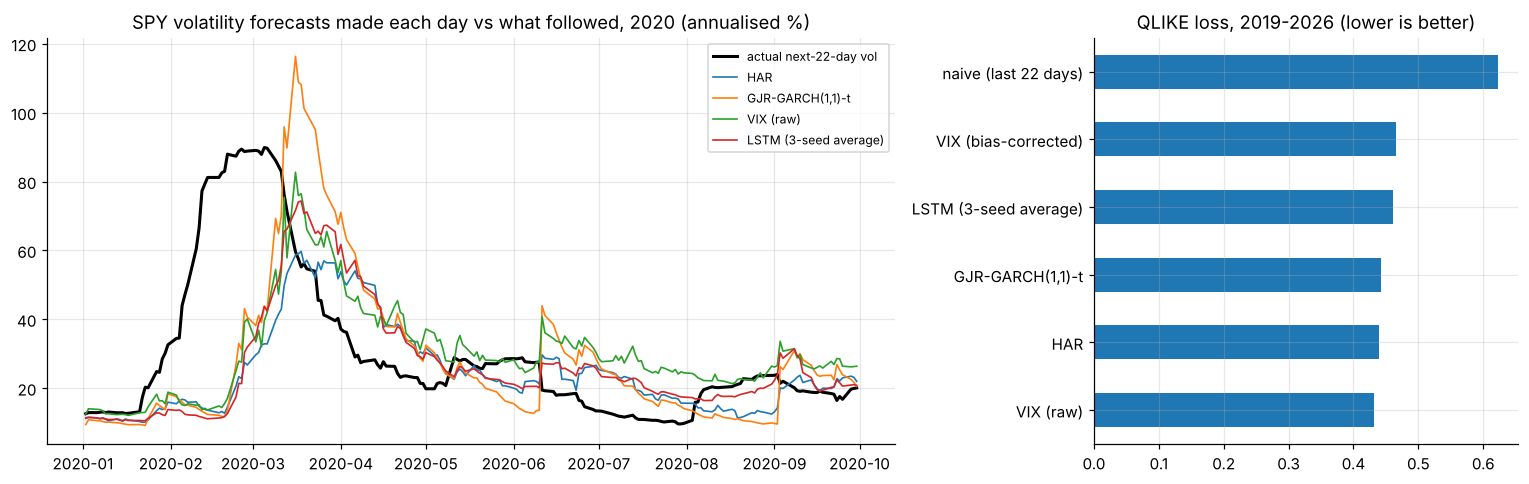

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
w = E["2020-01-01":"2020-09-30"]
ax[0].plot(w.index, 100 * w["actual"], "k", lw=2, label="actual next-22-day vol")
for n, c in [("HAR", "C0"), ("GJR-GARCH(1,1)-t", "C1"), ("VIX (raw)", "C2"), ("LSTM (3-seed average)", "C3")]:
    ax[0].plot(w.index, 100 * w[n], color=c, lw=1.1, label=n)
ax[0].set_title("SPY volatility forecasts made each day vs what followed, 2020 (annualised %)"); ax[0].legend(fontsize=8)
acc["QLIKE, all 2019-2026"].sort_values().plot.barh(ax=ax[1], color="C0"); ax[1].set_title("QLIKE loss, 2019-2026 (lower is better)")
plt.tight_layout(); plt.savefig(IMG / "vol_forecasts_covid.png", bbox_inches="tight"); plt.show()

## Findings
* **No method foresaw the Covid crash.** Every forecast made in late February 2020 was 15-20% annualised, while the next month's realised volatility turned out to be 80-90%. All models caught up only once the crash was under way. In March, GARCH then over-shot to 117%, because its estimated persistence carried the spike forward into April and May.
* **The VIX was the best single forecast overall and during the crash.** Over 2019-2026 the raw VIX has the lowest QLIKE loss (0.432), just ahead of HAR (0.440) and GJR-GARCH (0.443). In February-June 2020 it led clearly (2.89 vs 3.53 for HAR and 3.78 for GARCH), because option markets reprice faster than models built on past returns.
* **But the VIX is biased upward**, by 3.9 volatility points on average (the variance risk premium, see the derivatives repository). Correcting it with a regression fitted on past data gives the lowest RMSE overall (8.7 points) and nearly the lowest loss after Covid, but the correction fails in a crash.
* **The LSTM adds nothing over HAR.** It is competitive in calm markets (best post-Covid QLIKE, 0.202) but worse in the crash (4.71). Its gain over HAR is not significant (Diebold-Mariano p = 0.74), and no method is significantly better than HAR except the naive forecast, which is significantly worse (p = 0.001).
* **Practical reading:** for risk limits and VaR scaling, a simple HAR or GARCH model that blends in the VIX is as good as a neural network and far easier to explain and validate. No model gives early warning of a regime break like March 2020, so stress testing (notebook 4) remains necessary alongside model-based volatility.